# 🌍 World Happiness & Quality of Life Analytics

## Project Overview
An exploratory data analysis project to investigate global happiness levels and their relationship with economic, social, and health factors.

## Objectives
- Identify the happiest and least happy countries.
- Explore GDP and happiness relationships.
- Analyse social support and healthy life expectancy.
- Compare happiness across regions.
- Create meaningful visualizations using Matplotlib.

In [2]:
import csv
import numpy as np
import matplotlib.pyplot as plt


path="C:\\Users\\praha\\OneDrive\\Documents\\MyPythonProjects\\data-science-practice\\mini_projects\\02_Matplotlib\\World_Happines_Analysis\\data\\World_Happiness_2024.csv"
with open(path,"r",encoding='utf-8',newline='') as file:
    reader=csv.DictReader(file)
    data=list(reader)

print("Dsts loaded successfully!")
print("Total records    : ",len(data))
print('Number of columns: ',len(reader.fieldnames))
print("\nColumns : ",reader.fieldnames)
print()
for i in data[:3]:
    print(i)

Dsts loaded successfully!
Total records    :  143
Number of columns:  12

Columns :  ['Country name', 'Regional indicator', 'Ladder score', 'upperwhisker', 'lowerwhisker', 'Log GDP per capita', 'Social support', 'Healthy life expectancy', 'Freedom to make life choices', 'Generosity', 'Perceptions of corruption', 'Dystopia + residual']

{'Country name': 'Finland', 'Regional indicator': 'Western Europe', 'Ladder score': '7.741', 'upperwhisker': '7.815', 'lowerwhisker': '7.667', 'Log GDP per capita': '1.844', 'Social support': '1.572', 'Healthy life expectancy': '0.695', 'Freedom to make life choices': '0.859', 'Generosity': '0.142', 'Perceptions of corruption': '0.546', 'Dystopia + residual': '2.082'}
{'Country name': 'Denmark', 'Regional indicator': 'Western Europe', 'Ladder score': '7.583', 'upperwhisker': '7.665', 'lowerwhisker': '7.500', 'Log GDP per capita': '1.908', 'Social support': '1.520', 'Healthy life expectancy': '0.699', 'Freedom to make life choices': '0.823', 'Generosity':

# 2. Dataset Understanding & Data Preparation

## 2.1 Dataset Overview

The World Happiness Report 2024 dataset contains country-level happiness scores and several social, economic, and quality-of-life indicators.

- Original records: 143 countries
- Features: 12 columns
- Source: World Happiness Report 2024

## 2.2 Feature Understanding

| Feature | Description |
|---|---|
| Country name | Name of the country |
| Regional indicator | Geographical region |
| Ladder score | Overall happiness score |
| Upper whisker | Upper confidence interval |
| Lower whisker | Lower confidence interval |
| Log GDP per capita | Economic prosperity |
| Social support | Availability of social support |
| Healthy life expectancy | Expected healthy lifespan |
| Freedom to make life choices | Perceived personal freedom |
| Generosity | Generosity score |
| Perceptions of corruption | Perceived corruption |
| Dystopia + residual | Remaining score contribution |

### 2.3 Data Quality Assessment

Check the dataset for missing values and identify incomplete records before performing analysis.

### 2.4 Data Cleaning

Remove records containing missing values in the selected analysis features to maintain consistency.

### 2.5 Numerical Data Preparation

Convert the required numerical columns into NumPy arrays for statistical calculations and visualization.

### Expected Outcome

A clean dataset containing country names and numerical indicators, ready for statistical analysis.

In [3]:
for index,column in enumerate(reader.fieldnames,start=1):
    print(index, column)

1 Country name
2 Regional indicator
3 Ladder score
4 upperwhisker
5 lowerwhisker
6 Log GDP per capita
7 Social support
8 Healthy life expectancy
9 Freedom to make life choices
10 Generosity
11 Perceptions of corruption
12 Dystopia + residual


In [4]:
for column in reader.fieldnames:
    missing= sum(
        1 for row in data if row[column]==''
    )
    print(f"{column:30}: {missing}")

Country name                  : 0
Regional indicator            : 0
Ladder score                  : 0
upperwhisker                  : 0
lowerwhisker                  : 0
Log GDP per capita            : 3
Social support                : 3
Healthy life expectancy       : 3
Freedom to make life choices  : 3
Generosity                    : 3
Perceptions of corruption     : 3
Dystopia + residual           : 3


In [5]:
for row in data:
    for column in reader.fieldnames:
        if row[column]=="":
            print(f'{row['Country name']:5} : {column}')

Bahrain : Log GDP per capita
Bahrain : Social support
Bahrain : Healthy life expectancy
Bahrain : Freedom to make life choices
Bahrain : Generosity
Bahrain : Perceptions of corruption
Bahrain : Dystopia + residual
Tajikistan : Log GDP per capita
Tajikistan : Social support
Tajikistan : Healthy life expectancy
Tajikistan : Freedom to make life choices
Tajikistan : Generosity
Tajikistan : Perceptions of corruption
Tajikistan : Dystopia + residual
State of Palestine : Log GDP per capita
State of Palestine : Social support
State of Palestine : Healthy life expectancy
State of Palestine : Freedom to make life choices
State of Palestine : Generosity
State of Palestine : Perceptions of corruption
State of Palestine : Dystopia + residual


In [6]:
cleaned_data=[
    row for row in data 
    if all(row[column]!='' for column in reader.fieldnames)
]

print("Original records  : ",len(data))
print("Clean records     : ",len(cleaned_data))
print("Removed records   : ",len(data)-len(cleaned_data))

Original records  :  143
Clean records     :  140
Removed records   :  3


In [7]:
countries=[row['Country name'] for row in cleaned_data]
happiness=np.array([float(row['Ladder score']) for row in cleaned_data])
gdp=np.array([float(row['Log GDP per capita']) for row in cleaned_data])
social_support=np.array([float(row['Social support']) for row in cleaned_data])
life_expectancy=np.array([float(row['Healthy life expectancy']) for row in cleaned_data])
freedom=np.array([float(row['Freedom to make life choices']) for row in cleaned_data])
generosity=np.array([float(row['Generosity']) for row in cleaned_data])
corruption=np.array([float(row['Perceptions of corruption']) for row in cleaned_data])

print("Countries                : ",len(countries))
print("Happiness array shape    : ",happiness.shape)
print("GDP array shape          : ",gdp.shape)
print("First 5 happiness scores : ",happiness[:5])

Countries                :  140
Happiness array shape    :  (140,)
GDP array shape          :  (140,)
First 5 happiness scores :  [7.741 7.583 7.525 7.344 7.341]


# 3. Happiness Statistical Analysis

## Objective

Understand the overall distribution and statistical characteristics of happiness scores across the countries in the dataset.

## Statistical Measures

Calculate the following measures using NumPy:

1. **Mean:** Average happiness score.
2. **Median:** Middle value of the happiness scores.
3. **Standard Deviation:** Measures the spread of scores around the mean.
4. **Maximum:** Highest happiness score.
5. **Minimum:** Lowest happiness score.
6. **Range:** Difference between maximum and minimum scores.

## Methodology

- Calculate each statistical measure using the cleaned happiness array.
- Compare mean and median to understand the distribution.
- Examine standard deviation and range to understand score variation.

## Expected Outcome

A statistical summary that describes the overall happiness levels and variation among countries.

In [8]:
print("\tHAPPINESS STATISTICS")
print('-' *45)

print("Mean    : ",np.mean(happiness))
print('Median  : ',np.median(happiness))
print('Std     : ',np.std(happiness))
print('Maximum : ',np.max(happiness))
print('Minimum : ',np.min(happiness))
print("Range   : ",np.ptp(happiness))



	HAPPINESS STATISTICS
---------------------------------------------
Mean    :  5.530892857142858
Median  :  5.8004999999999995
Std     :  1.1770205647944216
Maximum :  7.741
Minimum :  1.721
Range   :  6.02


In [9]:
top_indices=np.argsort(happiness)[-10:][::-1]
print("\tTOP 10 HAPPIEST COUNTRIES")
print('-' *45)
for index in top_indices:
    print(f'{countries[index]:15} : {happiness[index]}')

	TOP 10 HAPPIEST COUNTRIES
---------------------------------------------
Finland         : 7.741
Denmark         : 7.583
Iceland         : 7.525
Sweden          : 7.344
Israel          : 7.341
Netherlands     : 7.319
Norway          : 7.302
Luxembourg      : 7.122
Switzerland     : 7.06
Australia       : 7.057


In [10]:
bottom_indices=np.argsort(happiness)[:10]
print("\tBOTTOM 10 HAPPIEST COUNTRIES")
print('-' *45)
for index in bottom_indices:
    print(f'{countries[index]:16} : {happiness[index]}')

	BOTTOM 10 HAPPIEST COUNTRIES
---------------------------------------------
Afghanistan      : 1.721
Lebanon          : 2.707
Lesotho          : 3.186
Sierra Leone     : 3.245
Congo (Kinshasa) : 3.295
Zimbabwe         : 3.341
Botswana         : 3.383
Malawi           : 3.421
Zambia           : 3.502
Eswatini         : 3.502


# 4. Top 10 Happiest Countries

## Objective

Identify the 10 happiest countries according to their 2024 happiness scores.

## Methodology

- Sort happiness scores using NumPy.
- Extract the indices of the 10 highest scores.
- Retrieve the corresponding country names.
- Arrange the countries in descending order of happiness score.

## Visualization

Create a horizontal bar chart to compare the happiness scores of the top 10 countries.

## Expected Outcome

A ranked list and visual comparison of the 10 happiest countries.

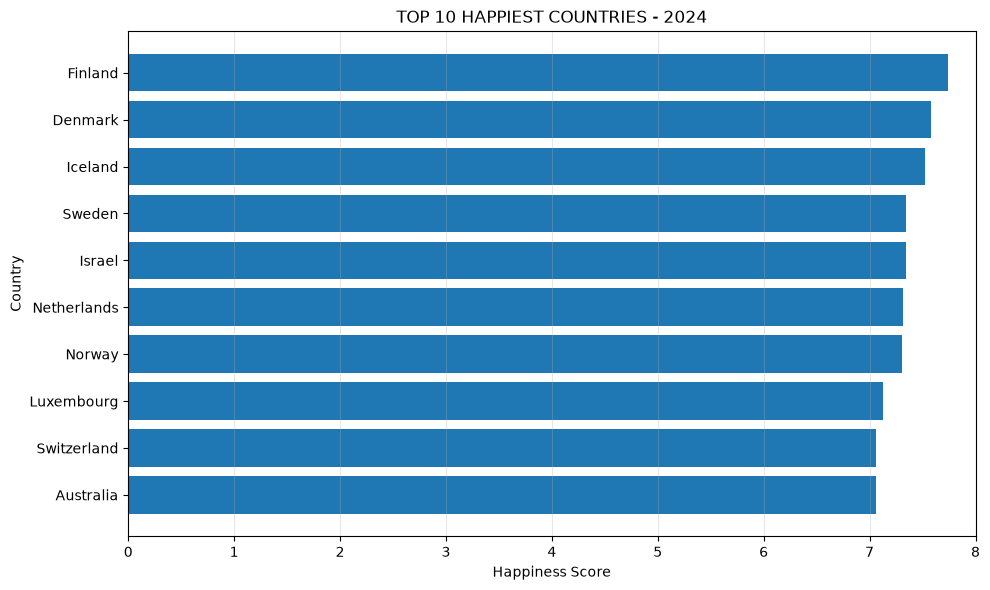

In [11]:
top_countries=[countries[i] for i in top_indices]
top_scores=[happiness[i] for i in top_indices]
plt.figure(figsize=(10,6))
plt.barh(top_countries,top_scores)
plt.title('TOP 10 HAPPIEST COUNTRIES - 2024')
plt.xlabel("Happiness Score")
plt.ylabel("Country")

plt.xlim(0,8)
plt.grid(axis='x',alpha=0.3)
plt.gca().invert_yaxis()
plt.savefig("C:\\Users\\praha\\OneDrive\\Documents\\MyPythonProjects\\data-science-practice\\mini_projects\\02_Matplotlib\\World_Happines_Analysis\\outputs\\top_10_happiest.png",dpi=300)
plt.tight_layout()
plt.show()


# 5. Bottom 10 Happiest Countries

## Objective

Identify the 10 countries with the lowest happiness scores in the 2024 dataset.

## Methodology

- Sort happiness scores using NumPy.
- Extract the indices of the 10 lowest scores.
- Retrieve the corresponding country names.
- Arrange the countries in ascending order of happiness score.

## Visualization

Create a horizontal bar chart to compare the happiness scores of the bottom 10 countries.

## Expected Outcome

A ranked list and visual comparison of the 10 countries with the lowest happiness scores.

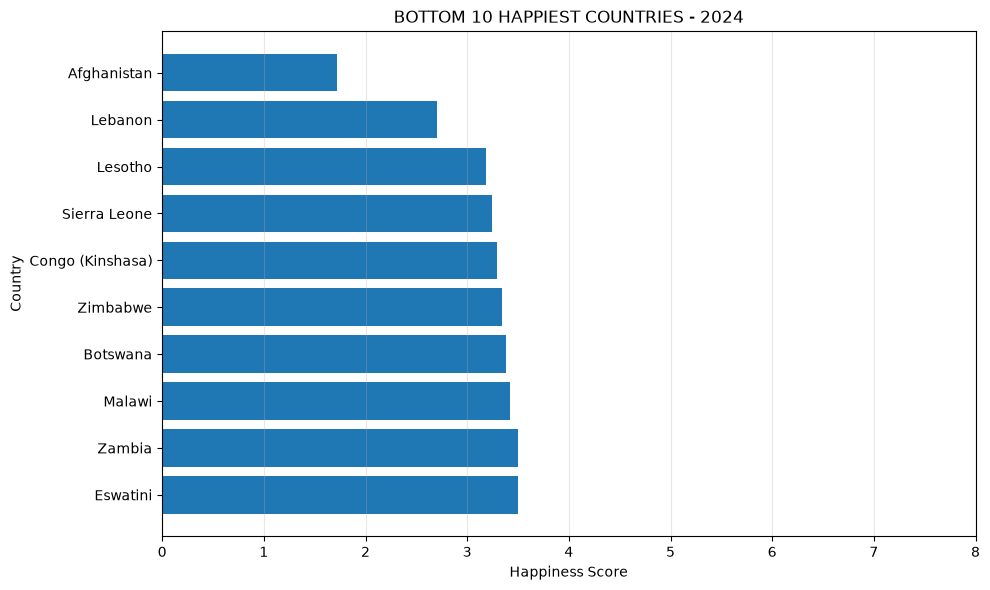

In [12]:
bottom_countries=[countries[i] for i in bottom_indices]
bottom_scores=[happiness[i] for i in bottom_indices]
plt.figure(figsize=(10,6))
plt.barh(bottom_countries,bottom_scores)
plt.title('BOTTOM 10 HAPPIEST COUNTRIES - 2024')
plt.xlabel("Happiness Score")
plt.ylabel("Country")

plt.xlim(0,8)
plt.grid(axis='x',alpha=0.3)
plt.gca().invert_yaxis()
plt.savefig("C:\\Users\\praha\\OneDrive\\Documents\\MyPythonProjects\\data-science-practice\\mini_projects\\02_Matplotlib\\World_Happines_Analysis\\outputs\\bottom_10_happiest.png",dpi=300)
plt.tight_layout()
plt.show()

## 5.1 Bottom 10 Countries — Results & Insights

### Ranking Results

| Rank | Country | Happiness Score |
|---:|---|---:|
| 1 | Afghanistan | 1.721 |
| 2 | Lebanon | 2.707 |
| 3 | Lesotho | 3.186 |
| 4 | Sierra Leone | 3.245 |
| 5 | Congo (Kinshasa) | 3.295 |
| 6 | Zimbabwe | 3.341 |
| 7 | Botswana | 3.383 |
| 8 | Malawi | 3.421 |
| 9 | Zambia | 3.502 |
| 10 | Eswatini | 3.502 |

### Key Insights

- Afghanistan recorded the lowest happiness score.
- The bottom 10 countries have scores ranging from 1.721 to 3.502.
- Zambia and Eswatini share the same happiness score.
- The results highlight differences in reported happiness across countries.

### Conclusion

The bottom 10 ranking identifies countries with the lowest reported happiness scores and provides a basis for investigating the economic and social factors associated with these differences.

# 6. Happiness Score Distribution

## Objective

Analyze how happiness scores are distributed across the 140 countries in the cleaned dataset.

## Methodology

- Use a histogram to visualize the frequency of happiness scores.
- Divide the scores into suitable bins.
- Identify the score ranges with the highest and lowest frequencies.
- Observe the overall shape and spread of the distribution.

## Visualization

Create a histogram using Matplotlib with:
- Appropriate bin intervals
- Clear title and axis labels
- Grid lines for readability

## Expected Outcome

A visual understanding of the distribution, concentration, and variation of happiness scores across countries.

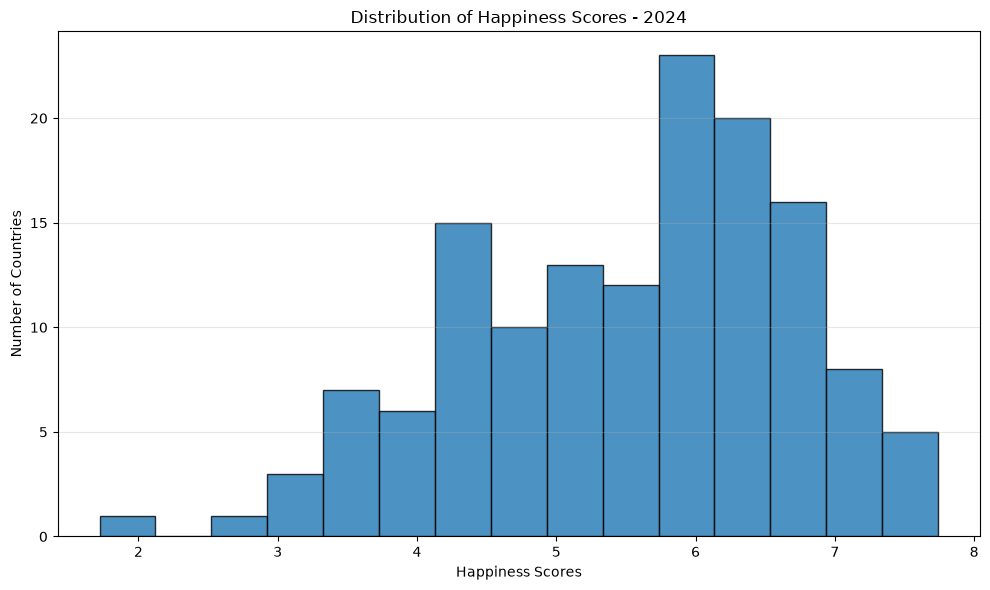

In [13]:
plt.figure(figsize=(10,6))
plt.hist(happiness,bins=15,edgecolor='black',alpha=0.8)
plt.title("Distribution of Happiness Scores - 2024")
plt.xlabel("Happiness Scores")
plt.ylabel("Number of Countries")
plt.grid(axis='y',alpha=0.3)
plt.savefig("C:\\Users\\praha\\OneDrive\\Documents\\MyPythonProjects\\data-science-practice\\mini_projects\\02_Matplotlib\\World_Happines_Analysis\\outputs\\happiness_score_distribution.png",dpi=300)
plt.tight_layout()
plt.show()

# 7. GDP vs Happiness

## Objective

Investigate the relationship between economic prosperity and happiness scores across countries.

## Methodology

- Use Log GDP per capita as the economic indicator.
- Compare GDP values with happiness scores.
- Examine whether higher GDP values are associated with higher happiness scores.
- Identify patterns, clusters, and unusual observations.

## Visualization

Create a scatter plot using Matplotlib.

- X-axis: Log GDP per capita
- Y-axis: Happiness Score
- Each point represents one country.

## Expected Outcome

Understand the relationship between economic prosperity and happiness and identify whether a positive association exists.

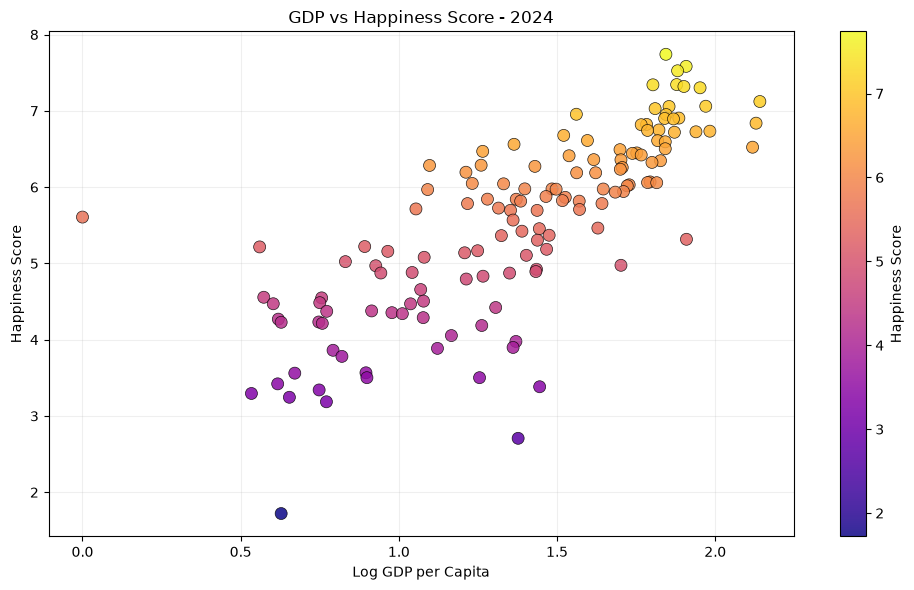

In [14]:
plt.figure(figsize=(10,6))
scatter=plt.scatter(
    gdp,
    happiness,
    c=happiness,
    cmap='plasma',
    s=75,
    alpha=0.85,
    edgecolors='black',linewidths=0.5
)
plt.colorbar(scatter,label="Happiness Score")
plt.title("GDP vs Happiness Score - 2024")
plt.xlabel("Log GDP per Capita")
plt.ylabel("Happiness Score")

plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("C:\\Users\\praha\\OneDrive\\Documents\\MyPythonProjects\\data-science-practice\\mini_projects\\02_Matplotlib\\World_Happines_Analysis\\outputs\\gdp_vs_happiness.png",dpi=300)
plt.show()


# 8. Social Support vs Happiness

## Objective

Analyze the relationship between social support and happiness scores across countries.

## Methodology

- Use Social Support as the independent variable.
- Use Happiness Score as the dependent variable.
- Compare both variables to identify patterns.
- Observe whether countries with stronger social support tend to report higher happiness.

## Visualization

Create a scatter plot with:
- X-axis: Social Support
- Y-axis: Happiness Score
- Gradient colours representing happiness scores.
- A colour bar for better interpretation.

## Expected Outcome

Understand how social support is associated with happiness levels across countries.

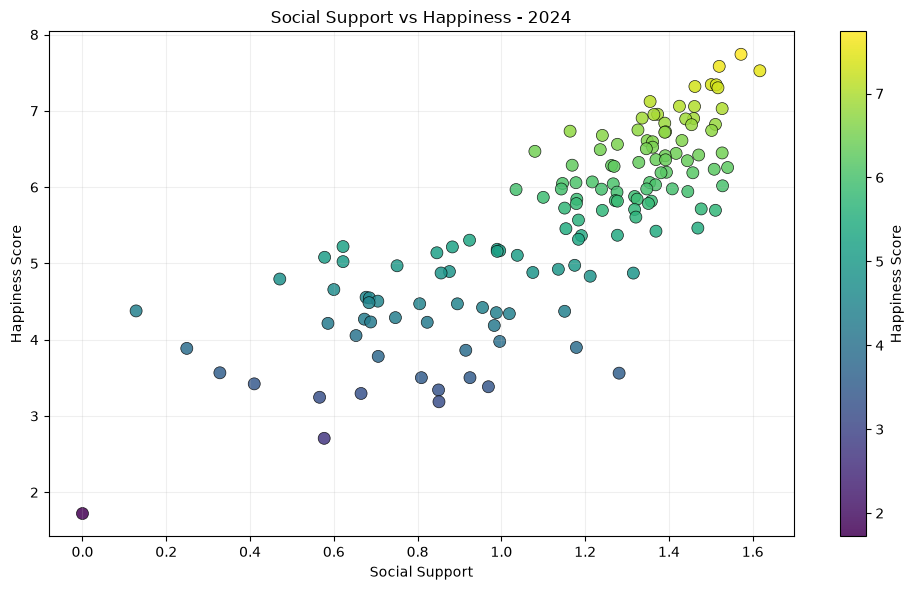

In [15]:
plt.figure(figsize=(10,6))
scatter=plt.scatter(
    social_support,
    happiness,
    c=happiness,
    cmap='viridis',
    s=75,
    alpha=0.85,
    edgecolors='black',linewidths=0.5
)
plt.colorbar(scatter,label="Happiness Score")
plt.title("Social Support vs Happiness - 2024")
plt.xlabel("Social Support")
plt.ylabel("Happiness Score")

plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("C:\\Users\\praha\\OneDrive\\Documents\\MyPythonProjects\\data-science-practice\\mini_projects\\02_Matplotlib\\World_Happines_Analysis\\outputs\\social_support_vs_happiness.png",dpi=300)
plt.show()

# 9. Regional Happiness Comparison

## Objective

Compare average happiness scores across different geographical regions.

## Methodology

- Identify all unique regional indicators.
- Calculate the average happiness score for each region.
- Sort regions based on their average scores.
- Compare regional happiness levels.

## Visualization

Create a colourful horizontal bar chart.

- Y-axis: Regions
- X-axis: Average Happiness Score
- Use a colour gradient to distinguish regional scores.
- Display average scores alongside the bars.

## Expected Outcome

Identify the happiest and least happy regions and understand geographical differences in reported happiness.

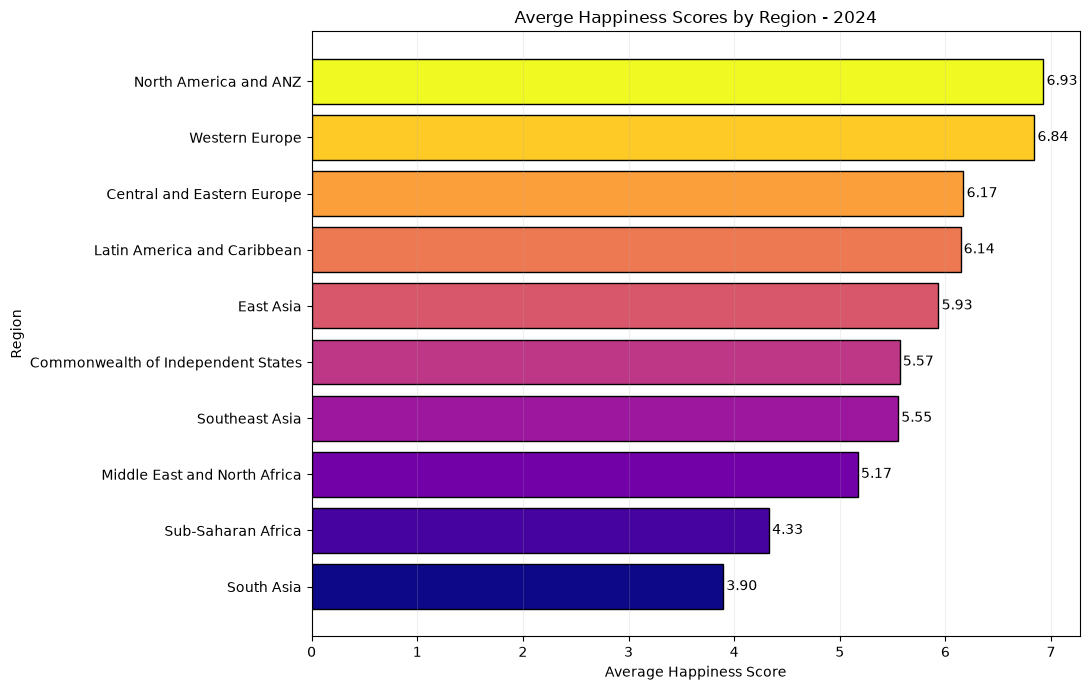

In [16]:
regions=sorted(set(
    row['Regional indicator'] for row in cleaned_data
))
regional_means=[]
for region in regions:
    scores=[
        float(row['Ladder score']) for row in cleaned_data if row['Regional indicator']==region
    ]

    regional_means.append(np.mean(scores))
regional_means=np.array(regional_means)
sorted_indices=np.argsort(regional_means)
sorted_regions=np.array(regions)[sorted_indices]
sorted_means=regional_means[sorted_indices]

plt.figure(figsize=(11,7))
colors=plt.cm.plasma(np.linspace(0,1,len(sorted_regions)))
bars=plt.barh(sorted_regions,sorted_means,color=colors,edgecolor='black')
for bar,score in zip(bars,sorted_means):
    plt.text(score+0.03,bar.get_y()+bar.get_height()/2,f'{score:.2f}',va='center')
plt.title("Averge Happiness Scores by Region - 2024")
plt.xlabel("Average Happiness Score")
plt.ylabel("Region")

plt.grid(axis='x',alpha=0.2)
plt.tight_layout()
plt.savefig("C:\\Users\\praha\\OneDrive\\Documents\\MyPythonProjects\\data-science-practice\\mini_projects\\02_Matplotlib\\World_Happines_Analysis\\outputs\\regional_happiness_comparison.png",dpi=300)
plt.show()

## 9.1 Regional Happiness — Results & Insights

### Regional Average Happiness Scores

| Rank | Region | Average Happiness Score |
|---:|---|---:|
| 1 | North America and ANZ | 6.93 |
| 2 | Western Europe | 6.84 |
| 3 | Central and Eastern Europe | 6.17 |
| 4 | Latin America and Caribbean | 6.14 |
| 5 | East Asia | 5.93 |
| 6 | Commonwealth of Independent States | 5.57 |
| 7 | Southeast Asia | 5.55 |
| 8 | Middle East and North Africa | 5.17 |
| 9 | Sub-Saharan Africa | 4.33 |
| 10 | South Asia | 3.90 |

### Key Insights

- North America and ANZ recorded the highest regional average happiness score (6.93).
- Western Europe ranked second with 6.84.
- South Asia recorded the lowest regional average (3.90).
- Sub-Saharan Africa had the second-lowest average (4.33).
- The difference between the highest and lowest regional averages is 3.03 points.

### Conclusion

The analysis reveals considerable differences in average happiness scores across geographical regions. North America and ANZ and Western Europe recorded the highest averages, while South Asia recorded the lowest.

These results provide a foundation for further investigation into the economic and social factors associated with happiness.

# 10. Happiness Score Variation

## Objective

Analyze the spread and variation of happiness scores across all countries using a box plot.

## Methodology

- Calculate the median happiness score.
- Identify the first quartile (Q1) and third quartile (Q3).
- Understand the interquartile range (IQR).
- Identify potential outliers.
- Examine the overall spread of happiness scores.

## Visualization

Create a box plot using Matplotlib with:
- Median line
- Quartiles
- Whiskers
- Outlier markers

## Expected Outcome

Understand the central distribution, variability, and unusual values in the happiness scores.

C:\Users\praha\AppData\Local\Temp\ipykernel_20204\3778501644.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  box=plt.boxplot(


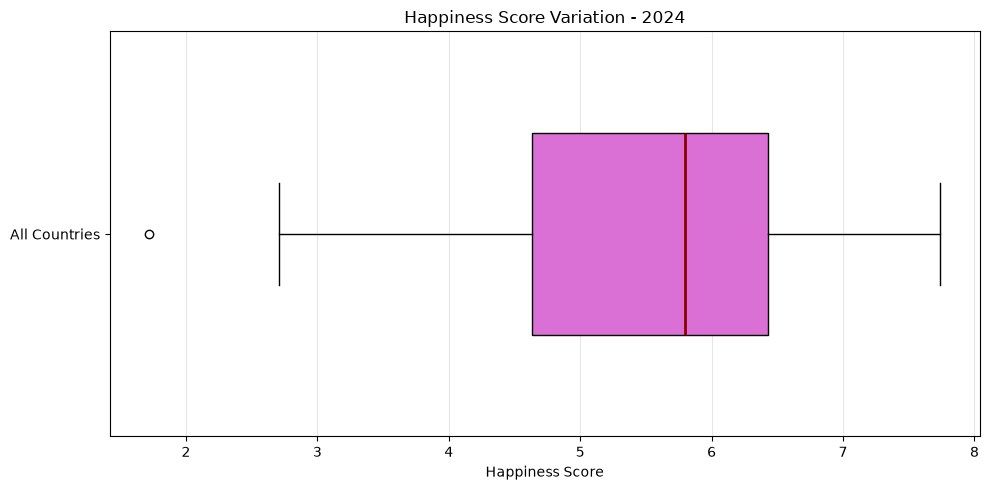

In [24]:
plt.figure(figsize=(10,5))
box=plt.boxplot(
    happiness,
    patch_artist=True,
    vert=False,
    widths=0.5
)
box['boxes'][0].set_facecolor('orchid')
box['boxes'][0].set_edgecolor('black')

box['medians'][0].set_color('darkred')
box['medians'][0].set_linewidth(2)

plt.title("Happiness Score Variation - 2024")
plt.xlabel("Happiness Score")
plt.yticks([1],["All Countries"])
plt.grid(axis='x',alpha=0.3)
plt.savefig("C:\\Users\\praha\\OneDrive\\Documents\\MyPythonProjects\\data-science-practice\\mini_projects\\02_Matplotlib\\World_Happines_Analysis\\outputs\\happiness_score_variation.png",dpi=300)
plt.tight_layout()
plt.show()

In [18]:
q1=np.percentile(happiness,25)
median=np.percentile(happiness,50)
q3=np.percentile(happiness,75)
iqr=q3-q1
print("Q1    : ",round(q1,3))
print("Median: ",round(median,3))
print("Q3    : ",round(q3,3))
print("IQR   : ",round(iqr,3))

Q1    :  4.632
Median:  5.8
Q3    :  6.426
IQR   :  1.795


In [19]:
lb=q1-1.5*iqr
up=q1+1.5*iqr

outliers=happiness[(lb>happiness)|(up<happiness)]
print(
    f'Lower Bound        : {round(lb,3)}\n'
    f'Upper bound        : {round(up,3)}\n'
    f'Number of outliers : {len(outliers)}\n'
    f'Outlier Scores     : {outliers}'
)

Lower Bound        : 1.94
Upper bound        : 7.324
Number of outliers : 6
Outlier Scores     : [7.741 7.583 7.525 7.344 7.341 1.721]


## 10.1 Outlier Detection — Results & Insights

### Statistical Results

- Lower Bound: 1.940
- Upper Bound: 7.324
- Total Outliers: 6

### Identified Outliers

Five countries have unusually high happiness scores, while one country has an unusually low score.

- Finland recorded the highest outlier score (7.741).
- Afghanistan recorded the lowest outlier score (1.721).
- The five highest-scoring countries exceed the upper IQR boundary.
- Afghanistan falls below the lower IQR boundary.

### Key Insight

Outliers represent unusually high or low observations compared with the overall distribution. They are not necessarily errors or invalid records.

### Conclusion

IQR-based analysis identified six unusual happiness scores, demonstrating how statistical techniques can detect extreme observations in real-world datasets.

# 11. Correlation Analysis

## Objective

Analyze the relationships between different quality-of-life indicators and happiness scores.

## Features for Analysis

- Log GDP per capita
- Social support
- Healthy life expectancy
- Freedom to make life choices
- Generosity
- Perceptions of corruption
- Happiness Score

## Methodology

- Calculate Pearson correlation coefficients using NumPy.
- Examine the relationship between each indicator and happiness.
- Identify positive and negative correlations.
- Compare the strength of relationships.

## Visualization

Create a correlation heatmap using Matplotlib to represent relationships between numerical variables through colour intensity.

## Expected Outcome

Identify which social and economic indicators have stronger relationships with happiness scores.

In [20]:
features=np.column_stack((
    happiness,
    gdp,
    social_support,
    life_expectancy,
    freedom,
    generosity,
    corruption
))

features_names=[
    'Happiness',
    'GDP',
    'Social Support',
    'Life Expectancy',
    'Freedom',
    'Generosity',
    'Corruption'
]
correlation_matrix=np.corrcoef(features,rowvar=False)
print("Features Count : ",len(features_names))
print("Features name  : ",features_names)
print("Matrix Shape   :",correlation_matrix.shape)
print(correlation_matrix)

Features Count :  7
Features name  :  ['Happiness', 'GDP', 'Social Support', 'Life Expectancy', 'Freedom', 'Generosity', 'Corruption']
Matrix Shape   : (7, 7)
[[ 1.          0.76850368  0.813542    0.75965938  0.64445115  0.13003823
   0.45182904]
 [ 0.76850368  1.          0.72684312  0.83025617  0.41488559 -0.05940473
   0.44422697]
 [ 0.813542    0.72684312  1.          0.70692406  0.4846411   0.07946581
   0.25086968]
 [ 0.75965938  0.83025617  0.70692406  1.          0.4010816   0.00714805
   0.39902576]
 [ 0.64445115  0.41488559  0.4846411   0.4010816   1.          0.22432285
   0.3441973 ]
 [ 0.13003823 -0.05940473  0.07946581  0.00714805  0.22432285  1.
   0.17266582]
 [ 0.45182904  0.44422697  0.25086968  0.39902576  0.3441973   0.17266582
   1.        ]]


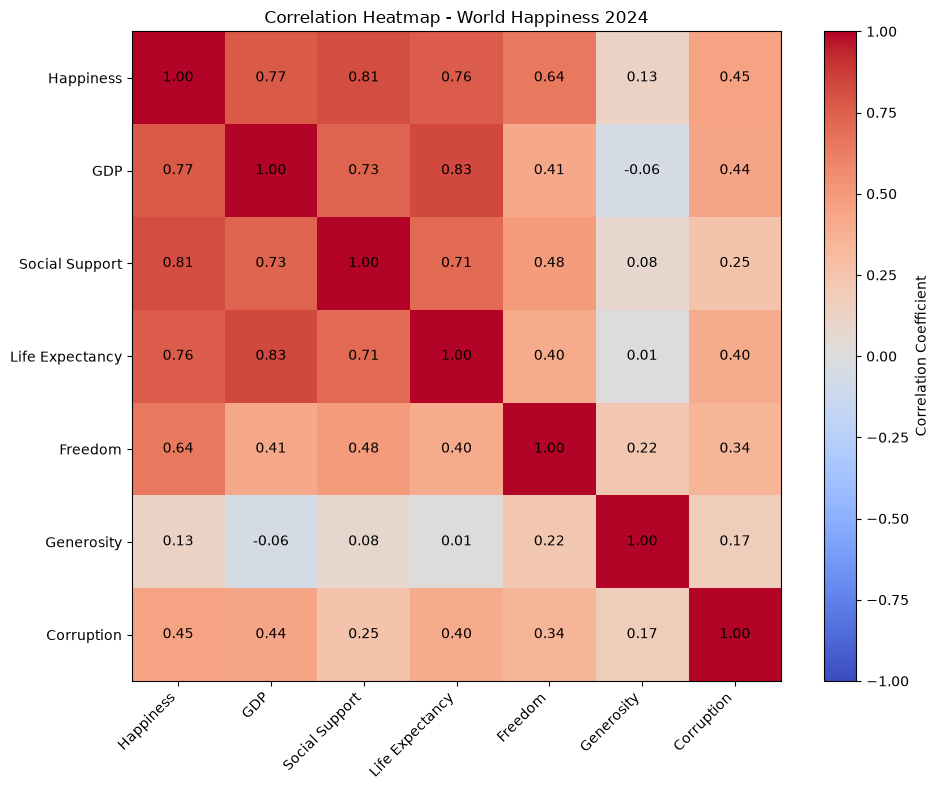

In [21]:
##visualize uing heatmap

plt.figure(figsize=(10,8))
plt.imshow(
    correlation_matrix,
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.colorbar(label='Correlation Coefficient')
plt.xticks(
    range(len(features_names)),
    features_names,
    rotation=45,
    ha='right'
)
plt.yticks(range(len(features_names)),features_names)

for i in range(len(features_names)):
    for j in range(len(features_names)):
        plt.text(j,i, f'{correlation_matrix[i,j]:.2f}',ha='center',va='center',color='black')

plt.title("Correlation Heatmap - World Happiness 2024")
plt.tight_layout()
plt.savefig('C:\\Users\\praha\\OneDrive\\Documents\\MyPythonProjects\\data-science-practice\\mini_projects\\02_Matplotlib\\World_Happines_Analysis\\outputs\\correlation_heatmap.png',dpi=300)
plt.show()

In [22]:
happiness_correlation=correlation_matrix[0,1:]
for name,value in zip(features_names[1:],happiness_correlation):
    print(f'{name:20} : {round(value,3)}')


GDP                  : 0.769
Social Support       : 0.814
Life Expectancy      : 0.76
Freedom              : 0.644
Generosity           : 0.13
Corruption           : 0.452


## 11.1 Correlation Analysis — Results & Insights

### Correlation Results

| Indicator | Correlation with Happiness |
|---|---:|
| Social Support | 0.814 |
| GDP per Capita | 0.769 |
| Healthy Life Expectancy | 0.760 |
| Freedom to Make Life Choices | 0.644 |
| Perceptions of Corruption | 0.452 |
| Generosity | 0.130 |

### Key Insights

- Social Support shows the strongest positive correlation with happiness (0.814).
- GDP per Capita has the second-strongest correlation (0.769).
- Healthy Life Expectancy also shows a strong positive correlation (0.760).
- Freedom to Make Life Choices has a moderate positive correlation (0.644).
- Perceptions of Corruption shows a moderate positive correlation (0.452).
- Generosity has the weakest positive correlation (0.130).

### Conclusion

Social Support, GDP per Capita, and Healthy Life Expectancy show particularly strong positive associations with happiness scores. These findings demonstrate the importance of examining multiple social, economic, and health-related indicators when studying quality of life.

Correlation indicates association, not causation.

# 12. Final World Happiness Dashboard

## Objective

Develop a comprehensive visual dashboard that summarizes the major findings of the World Happiness Report 2024 analysis.

## Dashboard Components

1. Top 10 Happiest Countries
2. Bottom 10 Happiest Countries
3. Average Happiness by Region
4. GDP per Capita vs Happiness

## Methodology

- Combine multiple visualizations using Matplotlib subplots.
- Present important happiness indicators in one figure.
- Apply consistent colours, titles, and labels.
- Maintain clear spacing and readability.

## Expected Outcome

A consolidated analytical dashboard that provides an overview of global happiness rankings, regional differences, and economic relationships.

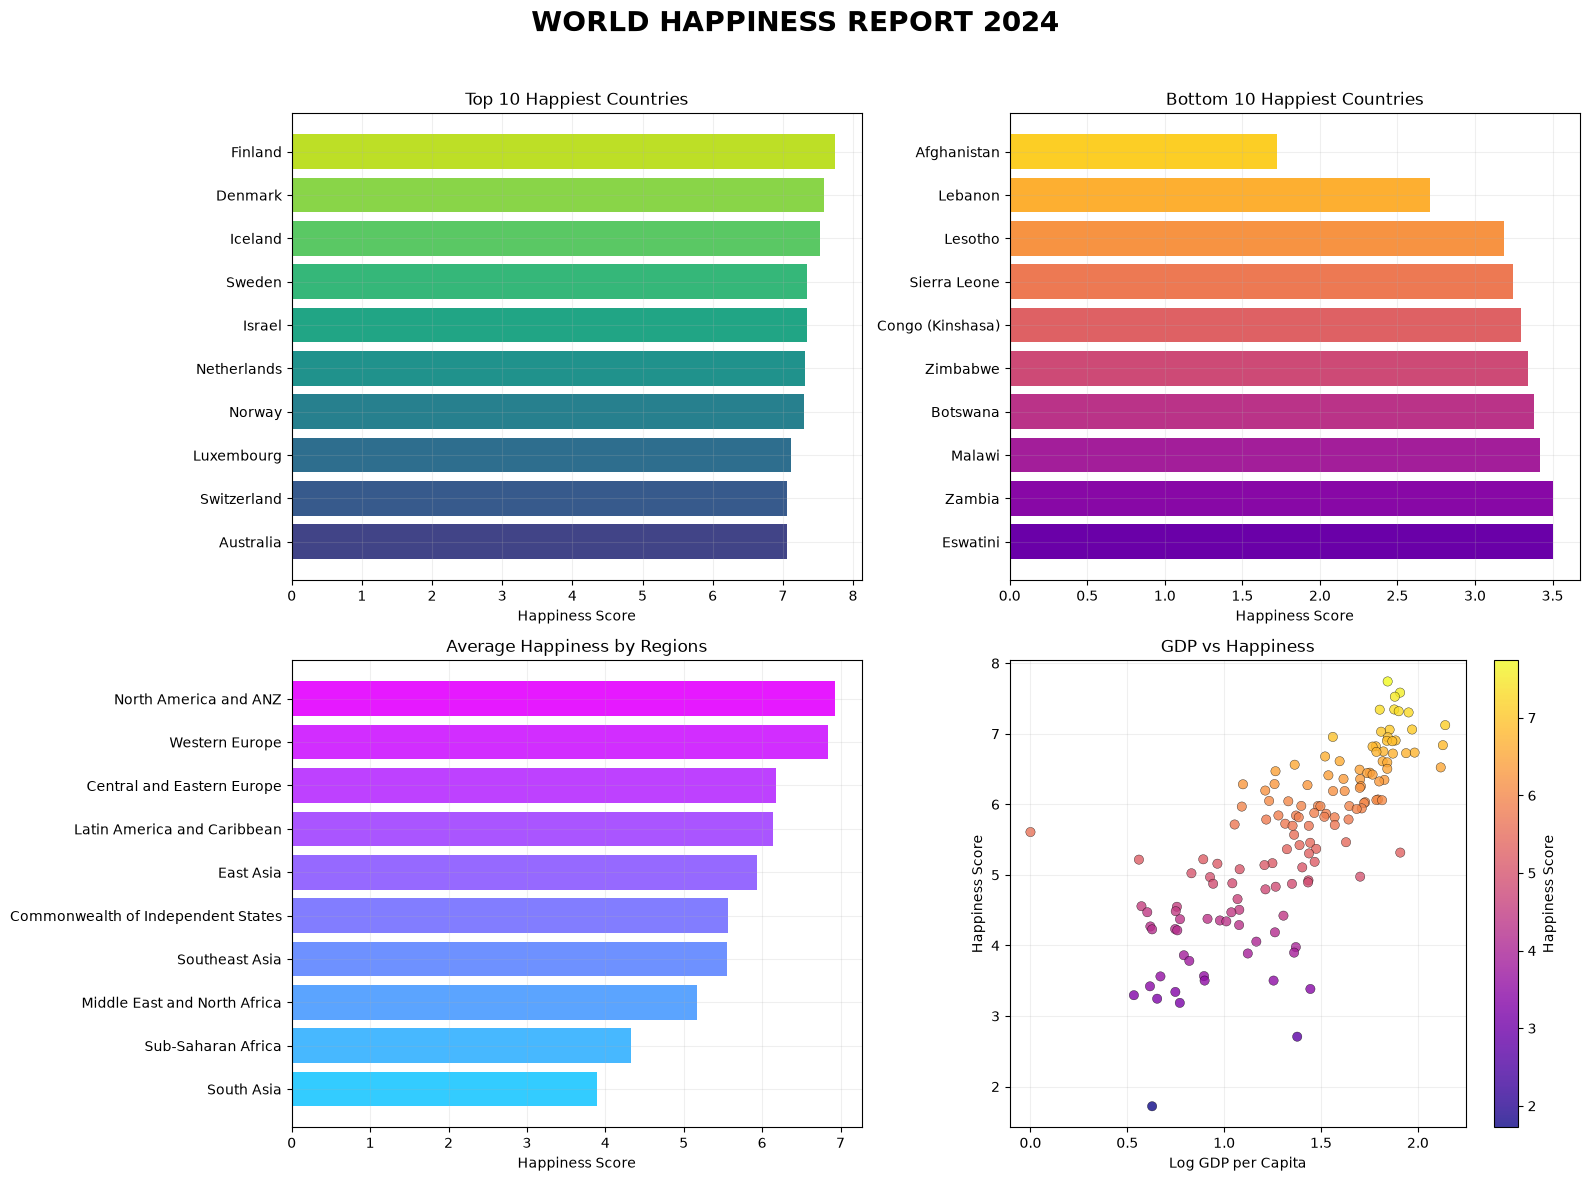

In [23]:
fig,ax=plt.subplots(2,2,figsize=(16,12))

fig.suptitle("WORLD HAPPINESS REPORT 2024",fontsize=20,fontweight='bold')

#1.TOP 10 HAPPIEST COUNTRIES

ax[0,0].barh(
    top_countries[::-1],
    top_scores[::-1],
    color=plt.cm.viridis(np.linspace(0.2,0.9,10))
)

ax[0,0].set_title("Top 10 Happiest Countries")
ax[0,0].set_xlabel("Happiness Score")

#2.BOTTOM 10 HAPPIEST COUNTRIES

ax[0,1].barh(
    bottom_countries[::-1],
    bottom_scores[::-1],
    color=plt.cm.plasma(np.linspace(0.2,0.9,10))
)

ax[0,1].set_title("Bottom 10 Happiest Countries")
ax[0,1].set_xlabel("Happiness Score")

#3.AVERAGE HAPPINESS BY REGION

ax[1,0].barh(
    sorted_regions,
    sorted_means,
    color=plt.cm.cool(np.linspace(0.2,0.9,len(sorted_regions)))
)

ax[1,0].set_title("Average Happiness by Regions")
ax[1,0].set_xlabel("Happiness Score")

#4.GDP vs HAPPINESS
scatter=ax[1,1].scatter(
    gdp,
    happiness,
    c=happiness,
    cmap='plasma',
    s=45,
    alpha=0.8,
    edgecolor='black',
    linewidths=0.3
)
ax[1,1].set_title("GDP vs Happiness")
ax[1,1].set_xlabel("Log GDP per Capita")
ax[1,1].set_ylabel("Happiness Score")

fig.colorbar(
    scatter,
    ax=ax[1,1],
    label="Happiness Score"
)

#FINAL FORMATTING

for a in ax.flat:
    a.grid(alpha=0.2)
plt.tight_layout(rect=[0,0,1,0.96])
plt.savefig("C:\\Users\\praha\\OneDrive\\Documents\\MyPythonProjects\\data-science-practice\\mini_projects\\02_Matplotlib\\World_Happines_Analysis\\outputs\\world_happiness_dashboard.png",dpi=300)
plt.show()


# 13. Key Findings & Conclusion

## 13.1 Key Findings

### Overall Happiness
- The average happiness score across the cleaned dataset was 5.5308.
- The median happiness score was 5.8000.
- The standard deviation was 1.1770.

### Country Rankings
- Finland ranked as the happiest country with a score of 7.741.
- Afghanistan recorded the lowest score of 1.721.

### Regional Comparison
- North America and ANZ recorded the highest regional average.
- South Asia recorded the lowest regional average.

### Statistical Analysis
- IQR-based analysis identified six outliers.
- The middle 50% of happiness scores had an IQR of 1.795.

### Correlation Analysis
- Social Support had the strongest positive correlation with happiness (0.814).
- GDP per Capita showed a correlation of 0.769.
- Healthy Life Expectancy showed a correlation of 0.760.
- Generosity showed the weakest positive correlation (0.130).

## 13.2 Conclusion

This project explored global happiness levels using the World Happiness Report 2024 dataset.

Using Python, NumPy, and Matplotlib, the analysis covered statistical measurements, country rankings, regional comparisons, data distribution, outlier detection, and correlation analysis.

The findings demonstrate that happiness is associated with multiple social, economic, and health-related indicators. Social support, economic prosperity, and healthy life expectancy showed particularly strong positive relationships with happiness.

This project strengthened practical skills in data preparation, numerical analysis, statistical interpretation, and professional data visualization.

## 13.3 Learning Outcomes

- Data loading and cleaning using Python.
- Numerical analysis using NumPy.
- Statistical calculations and outlier detection.
- Data visualization using Matplotlib.
- Correlation analysis.
- Analytical thinking and insight generation.
- Building a structured data science project.